# Nigerian Music Consumption

Scikit-learn offers a large array of methods to perform clustering. The type you choose will depend on your use case.

| Method Name | Use Case |
|------------|----------|
| K-Means | General purpose, inductive |
| Affinity Propagation | Many, uneven clusters, inductive |
| Mean-Shift | Many, uneven clusters, inductive |
| Spectral Clustering | Few, even clusters, transductive |
| Ward Hierarchical Clustering | Many, constrained clusters, transductive |
| Agglomerative Clustering | Many, constrained, non-Euclidean distances, transductive |
| DBSCAN | Non-flat geometry, uneven clusters, transductive |
| OPTICS | Non-flat geometry, uneven clusters with variable density, transductive |
| Gaussian Mixtures | Flat geometry, inductive |
| BIRCH | Large dataset with outliers, inductive |

## 🎓 'Transductive' vs. 'inductive'

Transductive inference is derived from observed training cases that map to specific test cases. Inductive inference is derived from training cases that map to general rules which are only then applied to test cases.

An example: Imagine you have a dataset that is only partially labelled. Some things are 'records', some 'cds', and some are blank. Your job is to provide labels for the blanks. If you choose an inductive approach, you'd train a model looking for 'records' and 'cds', and apply those labels to your unlabeled data. This approach will have trouble classifying things that are actually 'cassettes'. A transductive approach, on the other hand, handles this unknown data more effectively as it works to group similar items together and then applies a label to a group. In this case, clusters might reflect 'round musical things' and 'square musical things'.

## 🎓 'Non-flat' vs. 'flat' geometry

Derived from mathematical terminology, non-flat vs. flat geometry refers to the measure of distances between points by either 'flat' (Euclidean) or 'non-flat' (non-Euclidean) geometrical methods.

'Flat' in this context refers to Euclidean geometry (parts of which are taught as 'plane' geometry), and non-flat refers to non-Euclidean geometry. What does geometry have to do with machine learning? Well, as two fields that are rooted in mathematics, there must be a common way to measure distances between points in clusters, and that can be done in a 'flat' or 'non-flat' way, depending on the nature of the data. Euclidean distances are measured as the length of a line segment between two points. Non-Euclidean distances are measured along a curve. If your data, visualized, seems to not exist on a plane, you might need to use a specialized algorithm to handle it.

## 🎓 'Distances'

Clusters are defined by their distance matrix, e.g. the distances between points. This distance can be measured in a few ways. Euclidean clusters are defined by the average of the point values, and contain a 'centroid' or center point. Distances are thus measured by the distance to that centroid. Non-Euclidean distances refer to 'clustroids', the point closest to other points. Clustroids in turn can be defined in various ways.

## 🎓 'Constrained'

Constrained Clustering introduces 'semi-supervised' learning into this unsupervised method. The relationships between points are flagged as 'cannot link' or 'must-link' so some rules are forced on the dataset.

An example: If an algorithm is set free on a batch of unlabelled or semi-labelled data, the clusters it produces may be of poor quality. In the example above, the clusters might group 'round music things' and 'square music things' and 'triangular things' and 'cookies'. If given some constraints, or rules to follow ("the item must be made of plastic", "the item needs to be able to produce music") this can help 'constrain' the algorithm to make better choices.

## 🎓 'Density'

Data that is 'noisy' is considered to be 'dense'. The distances between points in each of its clusters may prove, on examination, to be more or less dense, or 'crowded' and thus this data needs to be analyzed with the appropriate clustering method.

## Clustering algorithms
There are over 100 clustering algorithms, and their use depends on the nature of the data at hand. Let's discuss some of the major ones:

- Hierarchical clustering. If an object is classified by its proximity to a nearby object, rather than to one farther away, clusters are formed based on their members' distance to and from other objects. Scikit-learn's agglomerative clustering is hierarchical.


- Centroid clustering. This popular algorithm requires the choice of 'k', or the number of clusters to form, after which the algorithm determines the center point of a cluster and gathers data around that point. K-means clustering is a popular version of centroid clustering. The center is determined by the nearest mean, thus the name. The squared distance from the cluster is minimized.

- Distribution-based clustering. Based in statistical modeling, distribution-based clustering centers on determining the probability that a data point belongs to a cluster, and assigning it accordingly. Gaussian mixture methods belong to this type.

- Density-based clustering. Data points are assigned to clusters based on their density, or their grouping around each other. Data points far from the group are considered outliers or noise. DBSCAN, Mean-shift and OPTICS belong to this type of clustering.

- Grid-based clustering. For multi-dimensional datasets, a grid is created and the data is divided amongst the grid's cells, thereby creating clusters.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("../Data/nigerian-songs.csv")
df.head()

,name,album,artist,artist_top_genre,release_date,length,popularity,danceability,acousticness,energy,instrumentalness,liveness,loudness,speechiness,tempo,time_signature
0,Sparky,Mandy & The Jungle,Cruel Santino,alternative r&b,2019,144000,48,0.666,0.8510,0.420,0.534000,0.1100,-6.699,0.0829,133.015,5
1,shuga rush,EVERYTHING YOU HEARD IS TRUE,Odunsi (The Engine),afropop,2020,89488,30,0.710,0.0822,0.683,0.000169,0.1010,-5.640,0.3600,129.993,3
2,LITT!,LITT!,AYLØ,indie r&b,2018,207758,40,0.836,0.2720,0.564,0.000537,0.1100,-7.127,0.0424,130.005,4
3,Confident / Feeling Cool,Enjoy Your Life,Lady Donli,nigerian pop,2019,175135,14,0.894,0.7980,0.611,0.000187,0.0964,-4.961,0.1130,111.087,4
4,wanted you,rare.,Odunsi (The Engine),afropop,2018,152049,25,0.702,0.1160,0.833,0.910000,0.3480,-6.044,0.0447,105.115,4


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 530 entries, 0 to 529
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              530 non-null    str    
 1   album             530 non-null    str    
 2   artist            530 non-null    str    
 3   artist_top_genre  530 non-null    str    
 4   release_date      530 non-null    int64  
 5   length            530 non-null    int64  
 6   popularity        530 non-null    int64  
 7   danceability      530 non-null    float64
 8   acousticness      530 non-null    float64
 9   energy            530 non-null    float64
 10  instrumentalness  530 non-null    float64
 11  liveness          530 non-null    float64
 12  loudness          530 non-null    float64
 13  speechiness       530 non-null    float64
 14  tempo             530 non-null    float64
 15  time_signature    530 non-null    int64  
dtypes: float64(8), int64(4), str(4)
memory usage: 66.4 KB


In [4]:
#make sure theres no null values
df.isnull().sum()

name                0
album               0
artist              0
artist_top_genre    0
release_date        0
length              0
popularity          0
danceability        0
acousticness        0
energy              0
instrumentalness    0
liveness            0
loudness            0
speechiness         0
tempo               0
time_signature      0
dtype: int64

In [5]:
#Describe the data:
df.describe()

,release_date,length,popularity,danceability,acousticness,energy,instrumentalness,liveness,loudness,speechiness,tempo,time_signature
count,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000
mean,2015.390566,222298.169811,17.507547,0.741619,0.265412,0.760623,0.016305,0.147308,-4.953011,0.130748,116.487864,3.986792
std,3.131688,39696.822259,18.992212,0.117522,0.208342,0.148533,0.090321,0.123588,2.464186,0.092939,23.518601,0.333701
min,1998.000000,89488.000000,0.000000,0.255000,0.000665,0.111000,0.000000,0.028300,-19.362000,0.027800,61.695000,3.000000
25%,2014.000000,199305.000000,0.000000,0.681000,0.089525,0.669000,0.000000,0.075650,-6.298750,0.059100,102.961250,4.000000
50%,2016.000000,218509.000000,13.000000,0.761000,0.220500,0.784500,0.000004,0.103500,-4.558500,0.097950,112.714500,4.000000
75%,2017.000000,242098.500000,31.000000,0.829500,0.403000,0.875750,0.000234,0.164000,-3.331000,0.177000,125.039250,4.000000
max,2020.000000,511738.000000,73.000000,0.966000,0.954000,0.995000,0.910000,0.811000,0.582000,0.514000,206.007000,5.000000


🤔 If we are working with clustering, an unsupervised method that does not require labeled data, why are we showing this data with labels? In the data exploration phase, they come in handy, but they are not necessary for the clustering algorithms to work. You could just as well remove the column headers and refer to the data by column number.

Text(0.5, 1.0, 'Top genres')

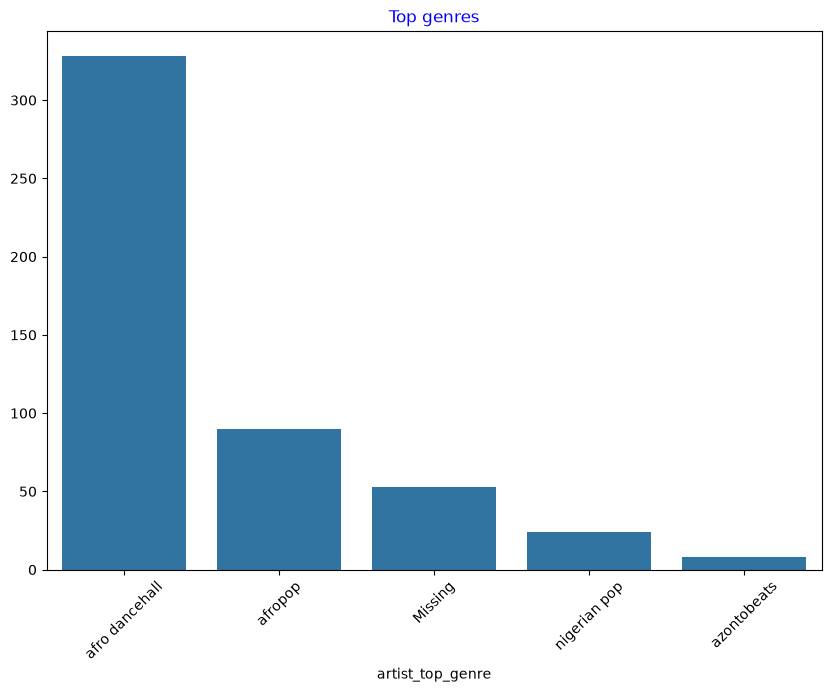

In [13]:
#Use a barplot to find out the most popular genres:
import seaborn as sns

top = df['artist_top_genre'].value_counts()
plt.figure(figsize=(10,7))
sns.barplot(x=top[:5].index,y=top[:5].values)
plt.xticks(rotation=45)
plt.title('Top genres',color = 'blue')

Note, when the top genre is described as 'Missing', that means that Spotify did not classify it, so let's get rid of it.

By far, the top three genres dominate this dataset. Let's concentrate on afro dancehall, afropop, and nigerian pop, additionally filter the dataset to remove anything with a 0 popularity value (meaning it was not classified with a popularity in the dataset and can be considered noise for our purposes):

Text(0.5, 1.0, 'Top genres')

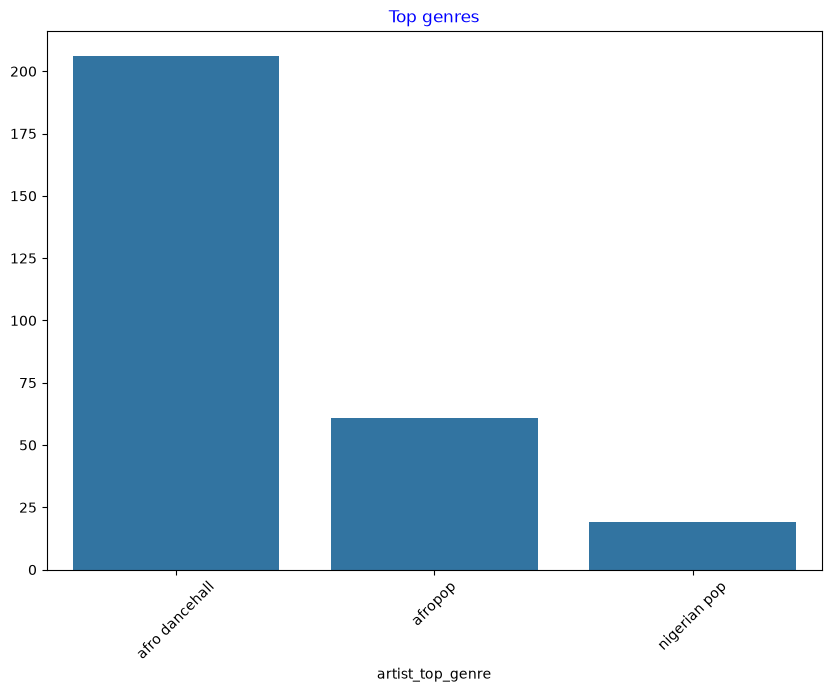

In [15]:
df = df[df['artist_top_genre'] != 'Missing']
df = df[(df['artist_top_genre'] == 'afro dancehall') | (df['artist_top_genre'] == 'afropop') | (df['artist_top_genre'] == 'nigerian pop')]
df = df[(df['popularity'] > 0)]
top = df['artist_top_genre'].value_counts()
plt.figure(figsize=(10,7))
sns.barplot(x=top.index,y=top.values)
plt.xticks(rotation=45)
plt.title('Top genres',color = 'blue')

<Axes: >

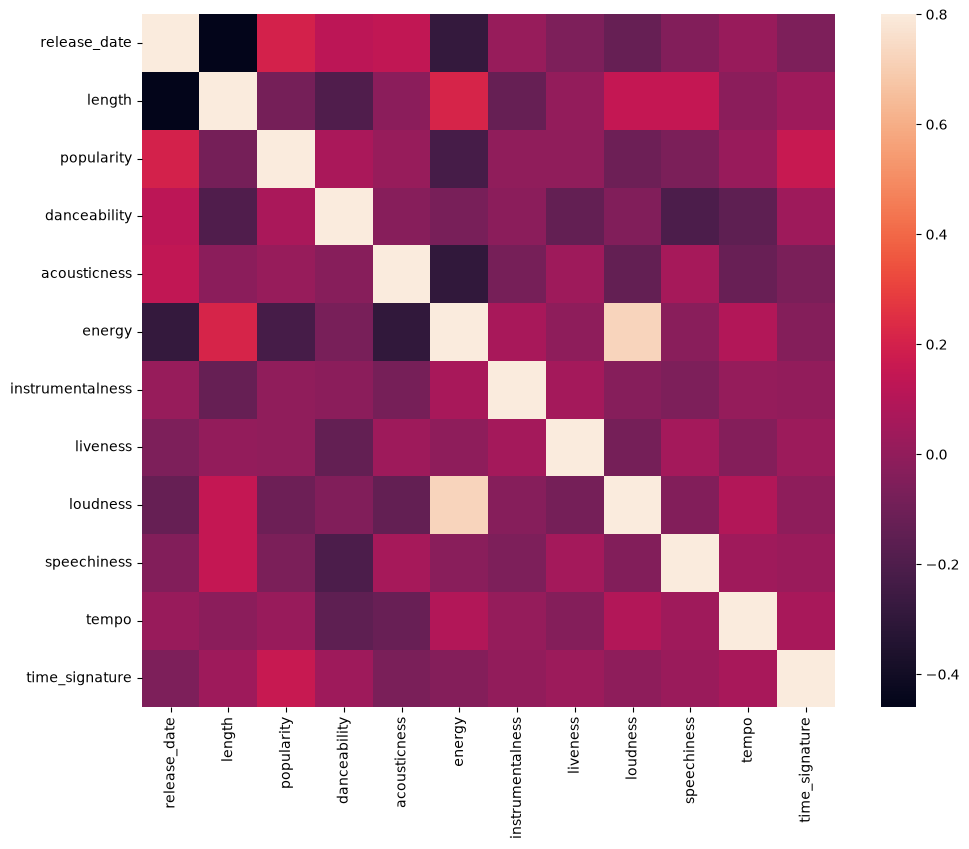

In [16]:
# Do a quick test to see if the data correlates in any particularly strong way

corrmat = df.corr(numeric_only=True)
f, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corrmat, vmax=.8, square=True)


The only strong correlation is between energy and loudness, which is not too surprising, given that loud music is usually pretty energetic. Otherwise, the correlations are relatively weak. It will be interesting to see what a clustering algorithm can make of this data.

## Exercise - data distribution
Are these three genres significantly different in the perception of their danceability, based on their popularity?

- Examine our top three genres data distribution for popularity and danceability along a given x and y axis.

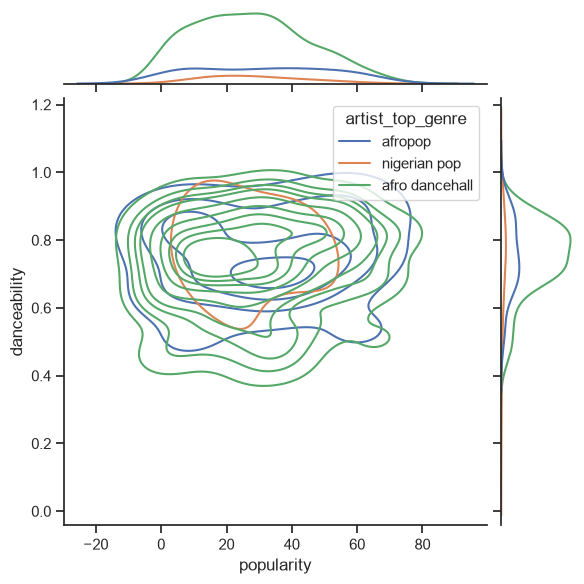

In [17]:
sns.set_theme(style="ticks")

g = sns.jointplot(
    data=df,
    x="popularity", y="danceability", hue="artist_top_genre",
    kind="kde",
)

You can discover concentric circles around a general point of convergence, showing the distribution of points.

🎓 Note that this example uses a KDE (Kernel Density Estimate) graph that represents the data using a continuous probability density curve. This allows us to interpret data when working with multiple distributions.

In general, the three genres align loosely in terms of their popularity and danceability. Determining clusters in this loosely-aligned data will be a challenge:



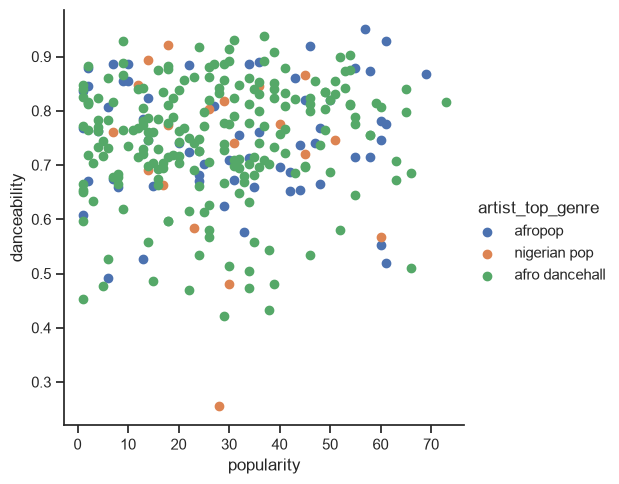

In [18]:
# Create a scatter plot
sns.FacetGrid(df, hue="artist_top_genre", height=5) \
   .map(plt.scatter, "popularity", "danceability") \
   .add_legend()

In general, for clustering, you can use scatterplots to show clusters of data, so mastering this type of visualization is very useful. In the next lesson, we will take this filtered data and use k-means clustering to discover groups in this data that seem to overlap in interesting ways.



## Variance
Variance is defined as "the average of the squared differences from the Mean" In the context of this clustering problem, it refers to data that the numbers of our dataset tend to diverge a bit too much from the mean.